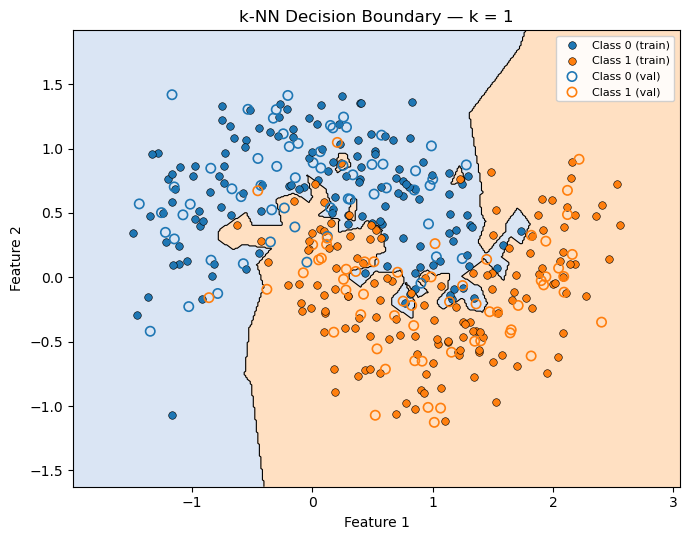

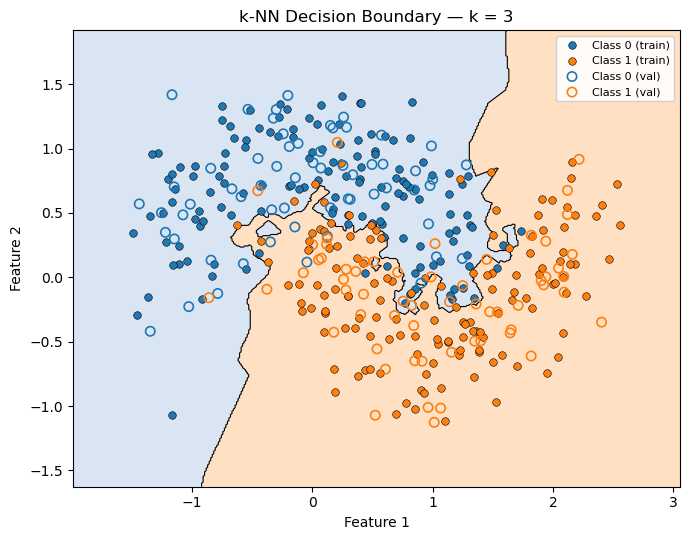

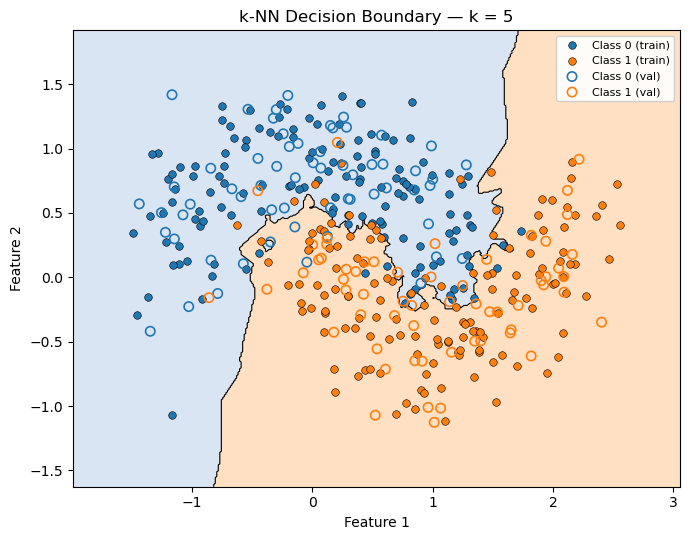

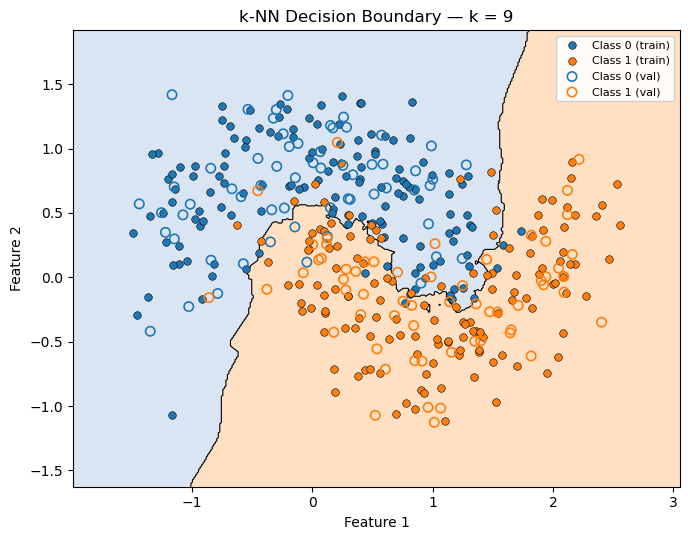

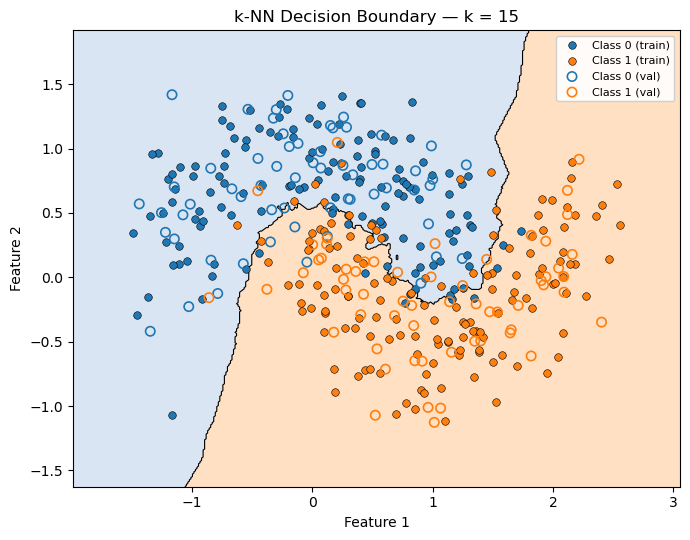

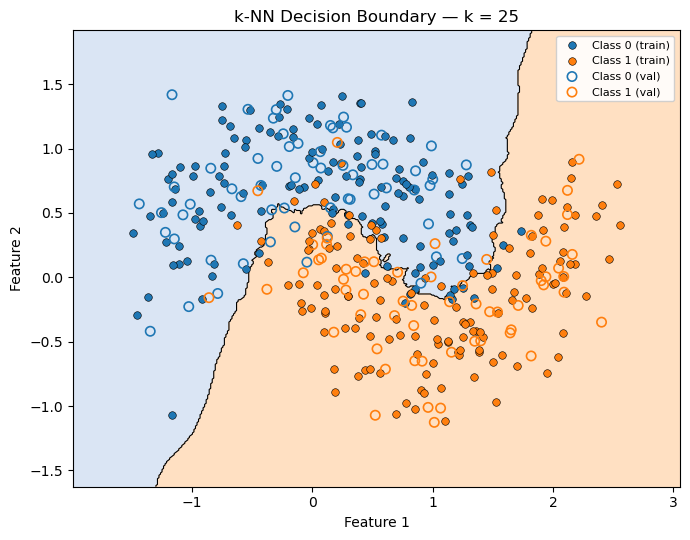

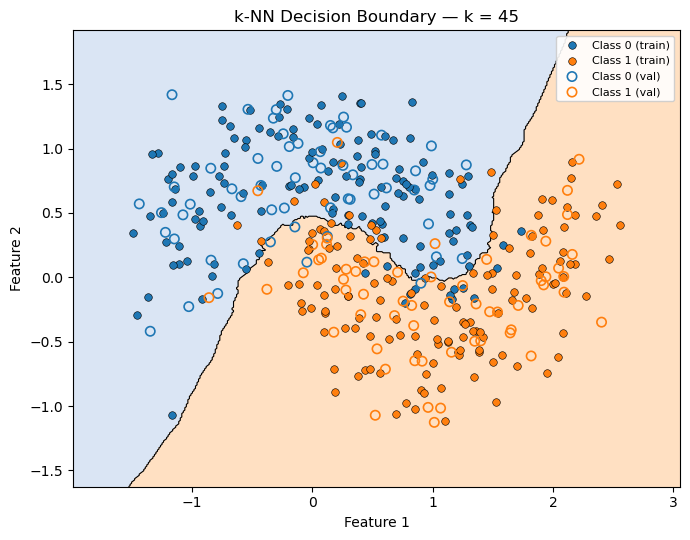

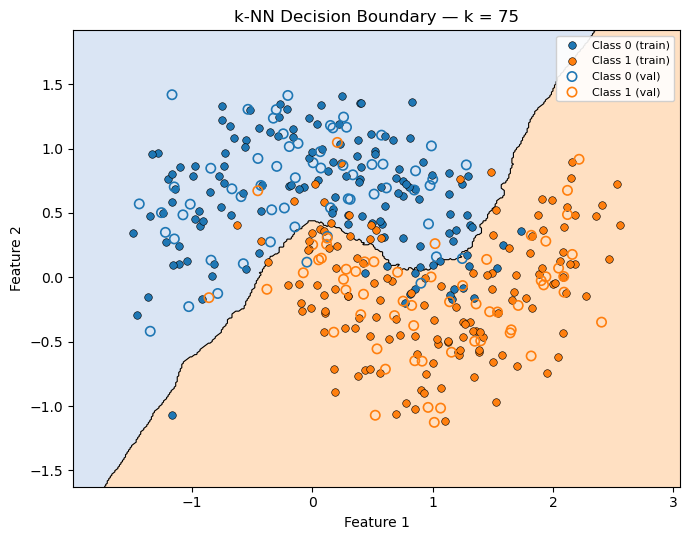

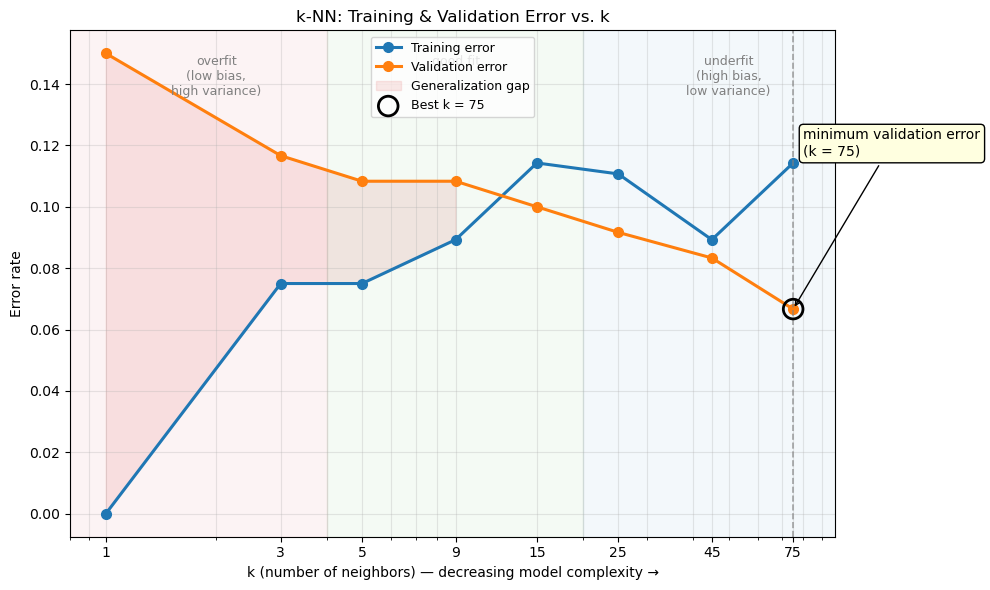

/Users/salvadorruizcorrea/opt/anaconda3/lib/python3.8/site-packages/threadpoolctl.py:1214: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


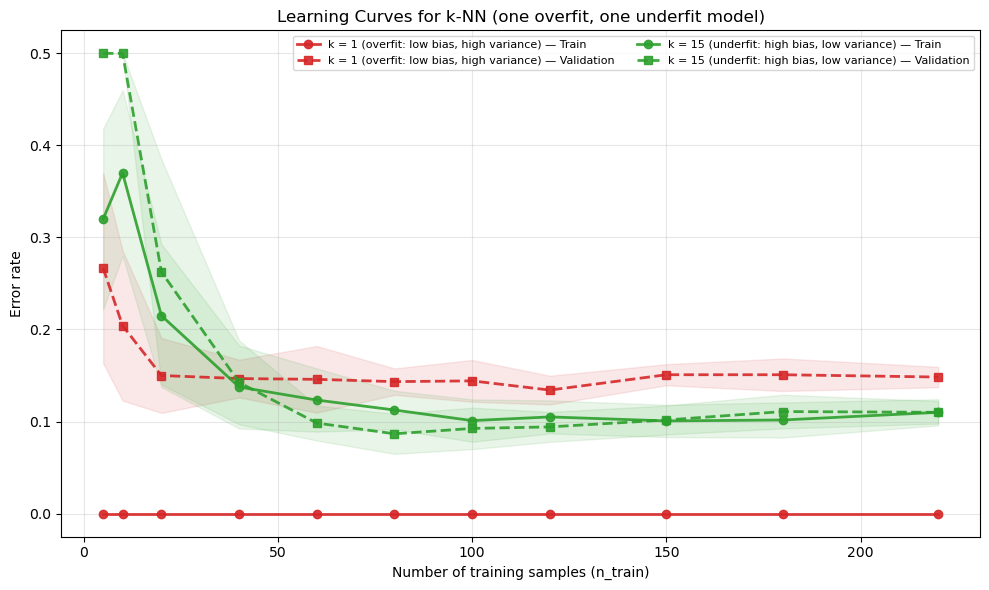


k-NN Classification — Model Complexity Report
  Total dataset      : 400
  Training pool size : 280
  Validation size    : 120
  Two-moons noise    : 0.3

    k |  Training Error |  Validation Error |      Gap
------------------------------------------------------
    1 |          0.0000 |            0.1500 |   0.1500
    3 |          0.0750 |            0.1167 |   0.0417
    5 |          0.0750 |            0.1083 |   0.0333
    9 |          0.0893 |            0.1083 |   0.0190
   15 |          0.1143 |            0.1000 |  -0.0143
   25 |          0.1107 |            0.0917 |  -0.0190
   45 |          0.0893 |            0.0833 |  -0.0060
   75 |          0.1143 |            0.0667 |  -0.0476

  Selected k (lowest validation error) : 75
  Training error of selected model     : 0.1143
  Validation error of selected model   : 0.0667

Learning-curve summary (averaged over repeats):
  k = 1  (overfit)   : train err stays ~0, val err high; large gap.
  k = 15 (underfit) : train & val er

In [2]:
# =============================================================================
# MODEL COMPLEXITY AND K-NEAREST NEIGHBORS CLASSIFICATION
# =============================================================================
#
# Demonstrates underfitting, appropriate fitting, and overfitting on a
# two-moons classification problem using k-NN with varying k.
# Also demonstrates learning curves: how train/validation error evolve
# as the number of training samples increases.
#
# Figures produced:
#   1. Decision-boundary plots for k = 1, 3, 5, 9, 15, 25, 45, 75
#   2. Training & validation error vs. k  (complexity curve)
#   3. Learning curves: error vs. n_train, for an overfit and an underfit k
#
# Console output:
#   Table of (k, training error, validation error, gap)
#   Learning-curve summary for selected k values
#
# Requirements: numpy, matplotlib, scikit-learn
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


# =============================================================================
# 1. REPRODUCIBILITY
# =============================================================================
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

N_TOTAL = 400
NOISE = 0.30
TEST_FRACTION = 0.30
K_VALUES = [1, 3, 5, 9, 15, 25, 45, 75]
LEARNING_KS = [1, 15]


# =============================================================================
# 2. DATA
# =============================================================================
X, y = make_moons(n_samples=N_TOTAL, noise=NOISE, random_state=RANDOM_SEED)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=TEST_FRACTION, random_state=RANDOM_SEED, stratify=y
)

x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400),
)
grid = np.c_[xx.ravel(), yy.ravel()]

cmap_bg = ListedColormap(["#aec7e8", "#ffbb78"])


# =============================================================================
# 3. FIT AND EVALUATE k-NN FOR A GIVEN k
# =============================================================================
def fit_knn(k):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    train_acc = accuracy_score(y_train, model.predict(X_train))
    val_acc = accuracy_score(y_val, model.predict(X_val))
    return model, train_acc, val_acc


# =============================================================================
# 4. DECISION-BOUNDARY PLOT FOR ONE k
# =============================================================================
def plot_decision_boundary(k, model):
    Z = model.predict(grid).reshape(xx.shape)

    fig, ax = plt.subplots(figsize=(7, 5.5))
    ax.contourf(xx, yy, Z, alpha=0.45, cmap=cmap_bg, levels=[-0.5, 0.5, 1.5])
    ax.contour(xx, yy, Z, colors="k", linewidths=0.8, levels=[0.5])

    ax.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1],
               s=30, c="#1f77b4", edgecolor="k", linewidth=0.4,
               label="Class 0 (train)", zorder=3)
    ax.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1],
               s=30, c="#ff7f0e", edgecolor="k", linewidth=0.4,
               label="Class 1 (train)", zorder=3)

    ax.scatter(X_val[y_val == 0, 0], X_val[y_val == 0, 1],
               s=45, facecolor="none", edgecolor="#1f77b4",
               linewidth=1.2, label="Class 0 (val)", zorder=4)
    ax.scatter(X_val[y_val == 1, 0], X_val[y_val == 1, 1],
               s=45, facecolor="none", edgecolor="#ff7f0e",
               linewidth=1.2, label="Class 1 (val)", zorder=4)

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.set_title(f"k-NN Decision Boundary — k = {k}")
    ax.legend(loc="upper right", fontsize=8, framealpha=0.9)
    plt.tight_layout()
    plt.savefig(f"knn_decision_boundary_k{k:02d}.png", dpi=120)
    plt.show()


# =============================================================================
# 5. FIT ALL K VALUES AND PLOT DECISION BOUNDARIES
# =============================================================================
def fit_all_ks(ks):
    results = {}
    for k in ks:
        model, train_acc, val_acc = fit_knn(k)
        results[k] = {
            "model": model,
            "train_acc": train_acc,
            "val_acc": val_acc,
        }
        plot_decision_boundary(k, model)
    return results


results = fit_all_ks(K_VALUES)

ks_arr = np.array(K_VALUES)
train_err = np.array([1 - results[k]["train_acc"] for k in K_VALUES])
val_err = np.array([1 - results[k]["val_acc"] for k in K_VALUES])
gap = val_err - train_err


# =============================================================================
# 6. COMPLEXITY CURVE: ERROR vs. k
# =============================================================================
def plot_error_vs_k(ks, train_err, val_err, best_k=None):
    # ---- FIX: ensure array inputs so `ks == best_k` is a boolean mask ----
    ks = np.asarray(ks)
    train_err = np.asarray(train_err)
    val_err = np.asarray(val_err)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(ks, train_err, "-o", lw=2.2, color="tab:blue",
            markersize=7, label="Training error")
    ax.plot(ks, val_err, "-o", lw=2.2, color="tab:orange",
            markersize=7, label="Validation error")

    ax.fill_between(ks, train_err, val_err,
                    where=(val_err >= train_err),
                    color="tab:red", alpha=0.10,
                    label="Generalization gap")

    if best_k is not None:
        idx = int(np.where(ks == best_k)[0][0])
        ax.axvline(best_k, color="gray", lw=1.2, linestyle="--", alpha=0.7)
        ax.scatter([best_k], [val_err[idx]], s=200, facecolor="none",
                   edgecolor="black", linewidth=2, zorder=5,
                   label=f"Best k = {best_k}")
        ax.annotate(f"minimum validation error\n(k = {best_k})",
                    xy=(best_k, val_err[idx]),
                    xytext=(best_k + 5, val_err[idx] + 0.05),
                    fontsize=10,
                    arrowprops=dict(arrowstyle="->", color="black", lw=1),
                    bbox=dict(boxstyle="round,pad=0.3",
                              facecolor="lightyellow", edgecolor="black"))

    ax.axvspan(0.5, 4, color="tab:red", alpha=0.05)
    ax.axvspan(4, 20, color="tab:green", alpha=0.05)
    ax.axvspan(20, 100, color="tab:blue", alpha=0.05)
    ymax = ax.get_ylim()[1]
    ax.text(2, ymax * 0.95, "overfit\n(low bias,\nhigh variance)",
            ha="center", va="top", fontsize=9, color="gray")
    ax.text(9, ymax * 0.95, "good fit",
            ha="center", va="top", fontsize=9, color="gray")
    ax.text(50, ymax * 0.95, "underfit\n(high bias,\nlow variance)",
            ha="center", va="top", fontsize=9, color="gray")

    ax.set_xscale("log")
    ax.set_xticks(ks)
    ax.set_xticklabels([str(k) for k in ks])
    ax.set_xlim(ks.min() * 0.8, ks.max() * 1.3)
    ax.set_xlabel("k (number of neighbors) — decreasing model complexity →")
    ax.set_ylabel("Error rate")
    ax.set_title("k-NN: Training & Validation Error vs. k")
    ax.grid(True, alpha=0.3, which="both")
    ax.legend(loc="upper center", fontsize=9)
    plt.tight_layout()
    plt.savefig("knn_error_vs_k.png", dpi=120)
    plt.show()


# =============================================================================
# 7. LEARNING CURVES: HOW ERROR CHANGES WITH THE NUMBER OF SAMPLES
# =============================================================================
def learning_curve_for_k(k, n_train_sizes, n_repeats=10):
    avg_train_err, avg_val_err = [], []
    std_train_err, std_val_err = [], []

    for n in n_train_sizes:
        train_errors, val_errors = [], []
        for _ in range(n_repeats):
            idx = rng.choice(len(X_train), size=n, replace=False)
            Xs, ys = X_train[idx], y_train[idx]

            model = KNeighborsClassifier(n_neighbors=min(k, n))
            model.fit(Xs, ys)

            train_errors.append(1 - accuracy_score(ys, model.predict(Xs)))
            val_errors.append(1 - accuracy_score(y_val, model.predict(X_val)))

        avg_train_err.append(np.mean(train_errors))
        avg_val_err.append(np.mean(val_errors))
        std_train_err.append(np.std(train_errors))
        std_val_err.append(np.std(val_errors))

    return (np.array(avg_train_err), np.array(avg_val_err),
            np.array(std_train_err), np.array(std_val_err))


def plot_learning_curves(ks, n_train_sizes):
    fig, ax = plt.subplots(figsize=(10, 6))

    colors = {ks[0]: "tab:red", ks[1]: "tab:green"}
    labels = {
        ks[0]: f"k = {ks[0]} (overfit: low bias, high variance)",
        ks[1]: f"k = {ks[1]} (underfit: high bias, low variance)",
    }

    for k in ks:
        tr, va, tr_std, va_std = learning_curve_for_k(k, n_train_sizes)
        c = colors[k]

        ax.plot(n_train_sizes, tr, "-o", lw=2, color=c,
                label=f"{labels[k]} — Train", alpha=0.9)
        ax.fill_between(n_train_sizes, tr - tr_std, tr + tr_std,
                        color=c, alpha=0.10)
        ax.plot(n_train_sizes, va, "--s", lw=2, color=c,
                label=f"{labels[k]} — Validation", alpha=0.9)
        ax.fill_between(n_train_sizes, va - va_std, va + va_std,
                        color=c, alpha=0.10)

    ax.set_xlabel("Number of training samples (n_train)")
    ax.set_ylabel("Error rate")
    ax.set_title("Learning Curves for k-NN (one overfit, one underfit model)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best", fontsize=8, ncol=2)
    plt.tight_layout()
    plt.savefig("knn_learning_curves.png", dpi=120)
    plt.show()


# =============================================================================
# 8. REPORTING
# =============================================================================
def print_table(ks, train_err, val_err):
    header = f"{'k':>5} | {'Training Error':>15} | {'Validation Error':>17} | {'Gap':>8}"
    print(header)
    print("-" * len(header))
    for k, tr, va in zip(ks, train_err, val_err):
        print(f"{k:>5d} | {tr:>15.4f} | {va:>17.4f} | {va - tr:>8.4f}")


def select_best_k(ks, val_err):
    ks = np.asarray(ks)                       # defensive
    return int(ks[int(np.argmin(val_err))])


# =============================================================================
# 9. MAIN
# =============================================================================
def main():
    best_k = select_best_k(K_VALUES, val_err)
    plot_error_vs_k(ks_arr, train_err, val_err, best_k=best_k)

    n_train_sizes = [5, 10, 20, 40, 60, 80, 100, 120, 150, 180, 220]
    n_train_sizes = [n for n in n_train_sizes if n <= len(X_train)]
    plot_learning_curves(LEARNING_KS, n_train_sizes)

    print()
    print("=" * 64)
    print("k-NN Classification — Model Complexity Report")
    print("=" * 64)
    print(f"  Total dataset      : {N_TOTAL}")
    print(f"  Training pool size : {len(X_train)}")
    print(f"  Validation size    : {len(X_val)}")
    print(f"  Two-moons noise    : {NOISE}")
    print()
    print_table(K_VALUES, train_err, val_err)

    print()
    print(f"  Selected k (lowest validation error) : {best_k}")
    best_idx = int(np.where(ks_arr == best_k)[0][0])
    print(f"  Training error of selected model     : {train_err[best_idx]:.4f}")
    print(f"  Validation error of selected model   : {val_err[best_idx]:.4f}")

    print()
    print("Learning-curve summary (averaged over repeats):")
    print(f"  k = {LEARNING_KS[0]}  (overfit)   : train err stays ~0, "
          f"val err high; large gap.")
    print(f"  k = {LEARNING_KS[1]:>2} (underfit) : train & val err both high; "
          f"small gap.")
    print()
    print("Educational interpretation:")
    print("  * Small k (e.g. 1)     -> low bias, high variance -> OVERFIT.")
    print("  * Medium k             -> balance -> GOOD FIT.")
    print("  * Large k              -> high bias, low variance -> UNDERFIT.")
    print("  * As n_train increases:")
    print("      - For overfit models, the gap shrinks and val error drops.")
    print("      - For underfit models, both errors plateau at a high value.")


if __name__ == "__main__":
    main()